1. Loading of Excel file

In [2]:
import pandas as pd

df = pd.read_excel("../data/raw/All_results_FPKM_Annot.xlsx")



c:\Users\imran\AppData\Local\Programs\Python\Python314\Lib\site-packages\openpyxl\worksheet\_reader.py:329: UserWarning: Conditional Formatting extension is not supported and will be removed
  warn(msg)


In [3]:
%pip install openpyxl


Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.2.1 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


2. Selection of only the columns I need

In [4]:
cols_keep = [
    # Gene annotation
    "Gene_ID", "gene_name", "gene_description", "tf_family", "gene_biotype",
    "kegg_pathway_name", "KOG Description",

    # Raw expression: WT
    "fpkm_WT_avg", "fpkm_WT_stdeva",
    "fpkm_WT_nP_avg", "fpkm_WT_nP_stdeva",

    # Raw expression: pdr2
    "fpkm_pdr2_P_avg", "fpkm_pdr2_P_stdeva",
    "fpkm_pdr2_nP_avg", "fpkm_pdr2_nP_stdeva",

    # Raw expression: l1l2
    "fpkm_l1l2_P_avg", "fpkm_l1l2_P_stdeva",
    "fpkm_l1l2_nP_avg", "fpkm_l1l2_nP_stdeva",

    # WT tissues
    "fpkm_WT_S_avg", "fpkm_WT_S_stdeva",
    "fpkm_WT_R_avg", "fpkm_WT_R_stdeva",

    # Differential expression: WT
    "fpkm_WT_nPvsWT_P_log2foldchange",
    "fpkm_WT_nPvsWT_P_pvalue",
    "fpkm_WT_nPvsWT_P_padjust",

    # Differential expression: pdr2
    "fpkm_pdr2_nPvspdr2_P_log2foldchange",
    "fpkm_pdr2_nPvspdr2_P_pvalue",
    "fpkm_pdr2_nPvspdr2_P_padjust",

    # Differential expression: l1l2
    "fpkm_l1l2_nPvsl1l2_P_log2foldchange",
    "fpkm_l1l2_nPvsl1l2_P_pvalue",
    "fpkm_l1l2_nPvsl1l2_P_padjust",

    # Genotype comparisons
    "fpkm_l1l2_PvsWT_P_log2foldchange",
    "fpkm_l1l2_PvsWT_P_pvalue",
    "fpkm_l1l2_PvsWT_P_padjust",

    "fpkm_pdr2_PvsWT_P_log2foldchange",
    "fpkm_pdr2_PvsWT_P_pvalue",
    "fpkm_pdr2_PvsWT_P_padjust",

    "fpkm_l1l2_Pvspdr2_P_log2foldchange",
    "fpkm_l1l2_Pvspdr2_P_pvalue",
    "fpkm_l1l2_Pvspdr2_P_padjust",

    # Root vs shoot
    "fpkm_WT_SvsWT_R_log2foldchange",
    "fpkm_WT_SvsWT_R_pvalue",
    "fpkm_WT_SvsWT_R_padjust",
]

df = df[cols_keep]


3. Renaming of columns

In [5]:
df = df.rename(columns={
    "fpkm_WT_avg": "WT_P",
    "fpkm_WT_nP_avg": "WT_nP",

    "fpkm_pdr2_P_avg": "pdr2_P",
    "fpkm_pdr2_nP_avg": "pdr2_nP",

    "fpkm_l1l2_P_avg": "l1l2_P",
    "fpkm_l1l2_nP_avg": "l1l2_nP",

    "fpkm_WT_nPvsWT_P_log2foldchange": "WT_log2FC",
    "fpkm_WT_nPvsWT_P_pvalue": "WT_pvalue",
    "fpkm_WT_nPvsWT_P_padjust": "WT_padjust",

    "fpkm_pdr2_nPvspdr2_P_log2foldchange": "pdr2_log2FC",
    "fpkm_pdr2_nPvspdr2_P_pvalue": "pdr2_pvalue",
    "fpkm_pdr2_nPvspdr2_P_padjust": "pdr2_padjust",

    "fpkm_l1l2_nPvsl1l2_P_log2foldchange": "l1l2_log2FC",
    "fpkm_l1l2_nPvsl1l2_P_pvalue": "l1l2_pvalue",
    "fpkm_l1l2_nPvsl1l2_P_padjust": "l1l2_padjust",
})


4. Conversion of numeric columns

In [6]:
numeric_cols = df.columns.drop(["Gene_ID", "gene_name", "gene_description"])
df[numeric_cols] = df[numeric_cols].apply(pd.to_numeric, errors="coerce")


5. Convert wide expression data into long format

In [7]:
expr_cols = ["WT_P", "WT_nP", "pdr2_P", "pdr2_nP", "l1l2_P", "l1l2_nP"]

df_expr = df.melt(
    id_vars=["Gene_ID", "gene_name"],
    value_vars=expr_cols,
    var_name="condition",
    value_name="expression"
)


6. Export cleaned tables

In [8]:
df_expr.to_csv("../data/processed/expression.csv", index=False)
df.to_csv("../data/processed/foldchange.csv", index=False)


7. Generation of annotation csv file. I will need it for later merger

In [9]:
df = pd.read_excel("../data/raw/All_results_FPKM_Annot.xlsx", engine="openpyxl")

annot_cols = [
    "Gene_ID", "gene_name", "gene_description", "tf_family", "gene_biotype",
    "kegg_pathway_name", "KOG Description", "range", "Range%", "sum", "Avrg", "express"
]

df_annot = df[annot_cols]
df_annot.to_csv("../data/processed/annotation.csv", index=False)



c:\Users\imran\AppData\Local\Programs\Python\Python314\Lib\site-packages\openpyxl\worksheet\_reader.py:329: UserWarning: Conditional Formatting extension is not supported and will be removed
  warn(msg)


Basic EDA

In [10]:
expr_cols = ["WT_P", "WT_nP", "pdr2_P", "pdr2_nP", "l1l2_P", "l1l2_nP"]

df_expr = df.melt(
    id_vars=["Gene_ID", "gene_name"],
    value_vars=expr_cols,
    var_name="condition",
    value_name="expression"
)


KeyError: "The following id_vars or value_vars are not present in the DataFrame: ['WT_P', 'WT_nP', 'pdr2_P', 'pdr2_nP', 'l1l2_P', 'l1l2_nP']"

In [ ]:
df_expr.describe()



,expression
count,234217.000000
mean,27.359942
std,108.713617
min,0.000000
25%,0.021857
50%,2.721241
75%,15.335602
max,3788.703319


EDA: Distribution plots "Shows if expression is skewed, bimodal, etc."

In [ ]:
%pip install matplotlib seaborn

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.2.1 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


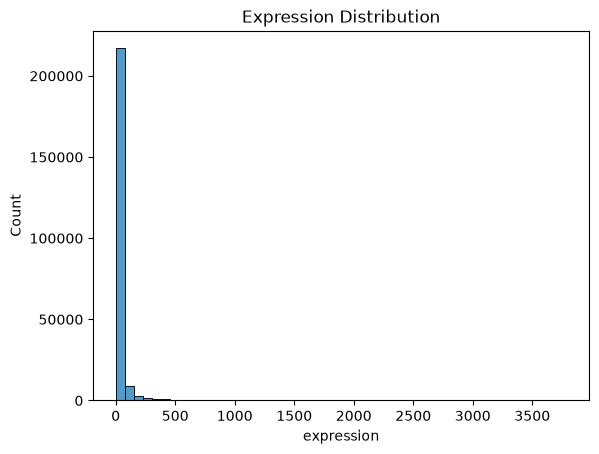

In [ ]:
import seaborn as sns
import matplotlib.pyplot as plt

sns.histplot(df_expr['expression'], bins=50)
plt.title("Expression Distribution")
plt.show()


Correlation between genotypes: "Shows similarity between WT, pdr2, l1l2."

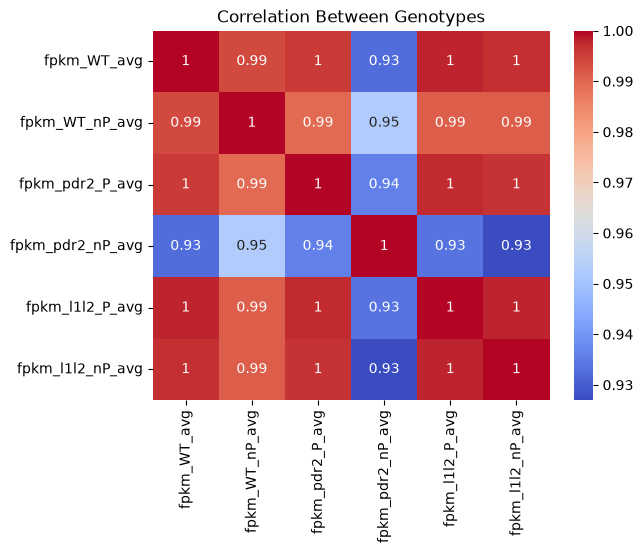

In [ ]:
import seaborn as sns
import matplotlib.pyplot as plt

expr_cols = [
    "fpkm_WT_avg",
    "fpkm_WT_nP_avg",
    "fpkm_pdr2_P_avg",
    "fpkm_pdr2_nP_avg",
    "fpkm_l1l2_P_avg",
    "fpkm_l1l2_nP_avg"
]

df_corr = df[expr_cols].corr()

sns.heatmap(df_corr, annot=True, cmap='coolwarm')
plt.title("Correlation Between Genotypes")
plt.show()



Expression Distribution:

What this will show:

Whether expression values are skewed

Whether +Pi and –Pi distributions differ

Whether Pi starvation globally reduces expression

Whether there are outliers or batch effects

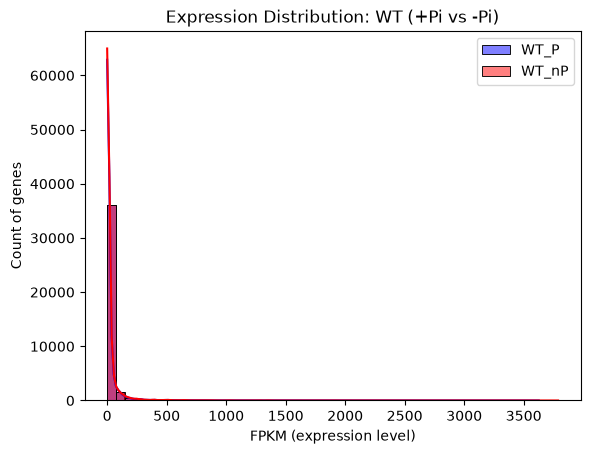

In [ ]:
import seaborn as sns
import matplotlib.pyplot as plt

sns.histplot(df['fpkm_WT_avg'], bins=50, color='blue', label='WT_P', kde=True)
sns.histplot(df['fpkm_WT_nP_avg'], bins=50, color='red', label='WT_nP', kde=True)
plt.legend()
plt.title("Expression Distribution: WT (+Pi vs -Pi)")
plt.xlabel("FPKM (expression level)")
plt.ylabel("Count of genes")
plt.show()


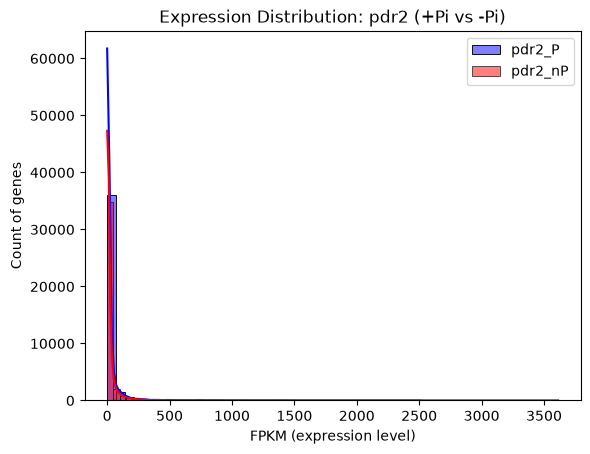

In [ ]:
sns.histplot(df['fpkm_pdr2_P_avg'], bins=50, color='blue', label='pdr2_P', kde=True)
sns.histplot(df['fpkm_pdr2_nP_avg'], bins=50, color='red', label='pdr2_nP', kde=True)
plt.legend()
plt.title("Expression Distribution: pdr2 (+Pi vs -Pi)")
plt.xlabel("FPKM (expression level)")
plt.ylabel("Count of genes")
plt.show()


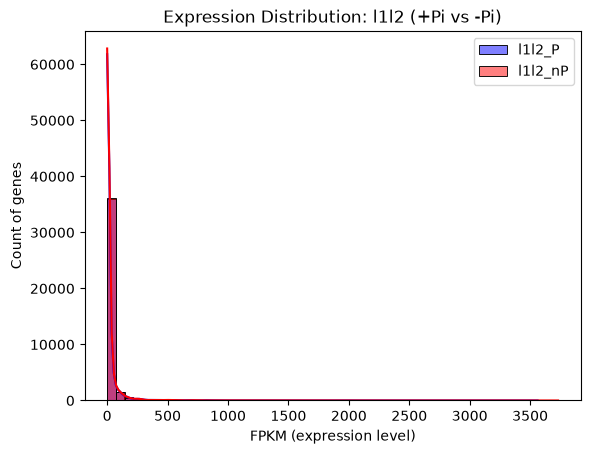

In [ ]:
sns.histplot(df['fpkm_l1l2_P_avg'], bins=50, color='blue', label='l1l2_P', kde=True)
sns.histplot(df['fpkm_l1l2_nP_avg'], bins=50, color='red', label='l1l2_nP', kde=True)
plt.legend()
plt.title("Expression Distribution: l1l2 (+Pi vs -Pi)")
plt.xlabel("FPKM (expression level)")
plt.ylabel("Count of genes")
plt.show()


DEGs (differentially expressed genes ) for WT

In [14]:
# WT differential expression
wt_fc = df['fpkm_WT_nPvsWT_P_log2foldchange']
wt_padj = df['fpkm_WT_nPvsWT_P_padjust']

# Upregulated
wt_up = df[(wt_fc > 1) & (wt_padj < 0.05)]

# Downregulated
wt_down = df[(wt_fc < -1) & (wt_padj < 0.05)]

print("WT upregulated genes:", wt_up.shape[0])
print("WT downregulated genes:", wt_down.shape[0])


WT upregulated genes: 375
WT downregulated genes: 101


In [16]:
wt_up.head(10)


,Gene_ID,gene_name,gene_description,tf_family,gene_biotype,kegg_pathway_name,KOG Description,range,Range%,sum,...,Mapman and other _Annotation-1.txt_PIR_SUPERFAMILY,Mapman and other _Annotation-1.txt_PROSITE,Mapman and other _Annotation-1.txt_PUBMED_ID,Mapman and other _Annotation-1.txt_REACTOME_PATHWAY,Mapman and other _Annotation-1.txt_SMART,Mapman and other _Annotation-1.txt_SP_COMMENT,Mapman and other _Annotation-1.txt_SP_COMMENT_TYPE,Mapman and other _Annotation-1.txt_SUPFAM,Mapman and other _Annotation-1.txt_UP_KEYWORDS,Mapman and other _Annotation-1.txt_UP_SEQ_FEATURE
82,AT1G01570,-,F22L4.11 protein [Source:UniProtKB/TrEMBL;Acc:...,-,protein_coding,.,.,2.310441,11.439156,20.197655,...,.,.,"11130712,24905498,",.,.,.,.,.,"Complete proteome,Reference proteome,Transferase,",.
261,AT1G02930,GSTF6,Glutathione S-transferase F6 [Source:UniProtKB...,GST_N,protein_coding,Glutathione metabolism,.,132.943868,26.406163,503.457727,...,.,"PS50404:PS50404,PS50405:PS50405,","11130712,12090627,12492832,14671022,15159623,1...",.,.,catalytic activity:RX + glutathione = HX + R-S...,"catalytic activity,function,induction,similari...","SSF47616:GST C-terminal domain-like,SSF52833:T...","Complete proteome,Cytoplasm,Detoxification,Pla...","chain:Glutathione S-transferase 1,domain:GST C..."
262,AT1G02930,GSTF6,Glutathione S-transferase F6 [Source:UniProtKB...,GST_N,protein_coding,Metabolic pathways,.,132.943868,26.406163,503.457727,...,.,"PS50404:PS50404,PS50405:PS50405,","11130712,12090627,12492832,14671022,15159623,1...",.,.,catalytic activity:RX + glutathione = HX + R-S...,"catalytic activity,function,induction,similari...","SSF47616:GST C-terminal domain-like,SSF52833:T...","Complete proteome,Cytoplasm,Detoxification,Pla...","chain:Glutathione S-transferase 1,domain:GST C..."
350,AT1G03600,PSB27-1,"Photosystem II repair protein PSB27-H1, chloro...",-,protein_coding,Photosynthesis,.,300.392305,49.570517,605.989855,...,.,.,"11130712,11826309,14729914,15028209,15322131,1...",.,.,"caution:Was also called At1g03610 (in AAM47889).,","caution,sequence caution,subcellular location,",.,"Chloroplast,Complete proteome,Direct protein s...","chain:Thylakoid lumenal protein At1g03610, chl..."
727,AT1G05000,-,Phosphotyrosine protein phosphatases superfami...,-,protein_coding,.,Predicted protein tyrosine phosphatase,22.562405,21.401637,105.423735,...,.,"PS00383:PS00383,","11130712,18433060,21409566,21952135,23118188,",.,.,catalytic activity:Protein tyrosine phosphate ...,"catalytic activity,similarity,subunit,",SSF52799:(Phosphotyrosine protein) phosphatase...,"3D-structure,Alternative splicing,Complete pro...","active site:Phosphocysteine intermediate,chain..."
776,AT1G05147,-,-,-,lncRNA,.,.,8.582169,46.290292,18.539890,...,.,.,.,.,.,.,.,.,.,.
1890,AT1G08645,-,-,-,protein_coding,.,.,7.380622,10.502349,70.275911,...,.,.,.,.,.,.,.,.,.,.
1892,AT1G08650,PPCK1,Phosphoenolpyruvate carboxylase kinase 1 [Sour...,Pkinase,protein_coding,.,.,51.682933,10.392360,497.316612,...,.,"PS00107:PS00107,PS00108:PS00108,PS50011:PS50011,","10571893,11130712,18771573,19397910,21423366,2...","R-ATH-2142691:R-ATH-2142691,R-ATH-3371453:R-AT...","SM00220:S_TKc,",similarity:Belongs to the protein kinase super...,"similarity,","SSF56112:Protein kinase-like (PK-like),","Alternative splicing,ATP-binding,Complete prot...",.
2149,AT1G09460,-,Carbohydrate-binding X8 domain superfamily pro...,-,protein_coding,.,.,29.177217,13.241287,220.350309,...,.,.,"11130712,",.,"SM00768:X8,",.,.,.,"Complete proteome,Reference proteome,Signal,",.
2313,AT1G09932,-,Phosphoglycerate mutase family protein [Source...,-,protein_coding,.,.,18.695608,24.616796,75.946556,...,.,.,"11130712,",.,"SM00855:SM00855,",.,.,"SSF53254:Phosphoglycerate mutase-like,","Complete proteome,Reference proteome,",.


In [17]:
wt_down.head(10)


,Gene_ID,gene_name,gene_description,tf_family,gene_biotype,kegg_pathway_name,KOG Description,range,Range%,sum,...,Mapman and other _Annotation-1.txt_PIR_SUPERFAMILY,Mapman and other _Annotation-1.txt_PROSITE,Mapman and other _Annotation-1.txt_PUBMED_ID,Mapman and other _Annotation-1.txt_REACTOME_PATHWAY,Mapman and other _Annotation-1.txt_SMART,Mapman and other _Annotation-1.txt_SP_COMMENT,Mapman and other _Annotation-1.txt_SP_COMMENT_TYPE,Mapman and other _Annotation-1.txt_SUPFAM,Mapman and other _Annotation-1.txt_UP_KEYWORDS,Mapman and other _Annotation-1.txt_UP_SEQ_FEATURE
390,AT1G03920,-,Non-specific serine/threonine protein kinase [...,Pkinase,protein_coding,.,.,5.389589,14.054673,38.347306,...,.,"PS00107:PS00107,PS00108:PS00108,PS50011:PS5001...","11130712,13678909,17237187,17317660,18433157,",.,"SM00133:S_TK_X,SM00220:S_TKc,",catalytic activity:ATP + a protein = ADP + a p...,"catalytic activity,similarity,","SSF56112:Protein kinase-like (PK-like),","ATP-binding,Complete proteome,Kinase,Nucleotid...",.
1531,AT1G07560,-,Probable LRR receptor-like serine/threonine-pr...,Pkinase,protein_coding,.,.,2.848326,36.040518,7.903120,...,.,"PS00107:PS00107,PS00108:PS00108,PS50011:PS50011,","11130712,21423366,24833385,",.,"SM00220:S_TKc,",.,.,"SSF52058:L domain-like,SSF56112:Protein kinase...","ATP-binding,Complete proteome,Glycoprotein,Kin...","active site:Proton acceptor,binding site:ATP,c..."
1570,AT1G07690,-,FUNCTIONS IN: molecular_function unknown; INVO...,-,protein_coding,.,.,2.166560,16.955769,12.777716,...,.,.,"11130712,",.,.,.,.,.,"Complete proteome,Membrane,Reference proteome,...",.
1708,AT1G08090,NRT2.1,High-affinity nitrate transporter 2.1 [Source:...,MFS_1,protein_coding,Nitrogen metabolism,.,957.126487,46.077827,2077.195388,...,.,.,"11130712,11165253,16157886,16415211,16415212,1...",.,.,.,.,"SSF103473:MFS general substrate transporter,","Cell membrane,Complete proteome,Membrane,Nitra...",.
2384,AT1G10320,-,Zinc finger CCCH domain-containing protein 5 [...,zf-CCCH,protein_coding,.,"U2 snRNP splicing factor, small subunit, and r...",7.699674,10.836659,71.052104,...,.,"PS50102:PS50102,PS50103:PS50103,","11130712,25387881,","R-ATH-72165:R-ATH-72165,","SM00356:ZnF_C3H1,SM00361:RRM_1,","sequence caution:Intron retention.,similarity:...","sequence caution,similarity,","SSF54928:RNA-binding domain, RBD,","Complete proteome,DNA-binding,Metal-binding,Re...",chain:Zinc finger CCCH domain-containing prote...
3022,AT1G14970,OFUT4,O-fucosyltransferase 4 [Source:UniProtKB/Swiss...,-,protein_coding,.,.,6.137701,10.069054,60.956087,...,PIRSF009360:uncharacterized conserved protein ...,.,"11130712,22923678,",.,.,.,.,.,"Complete proteome,Glycosyltransferase,Membrane...",.
3840,AT1G21160,-,Eukaryotic translation initiation factor 2 (eI...,GTP_EFTU,protein_coding,RNA transport,Translation initiation factor 5B (eIF-5B),8.286035,14.303403,57.930513,...,.,"PS51722:PS51722,","11130712,","R-ATH-72706:R-ATH-72706,",.,.,.,"SSF50447:Translation proteins,SSF52156:Initiat...","Coiled coil,Complete proteome,Initiation facto...",.
4654,AT1G27921,-,other RNA [Source:TAIR;Acc:AT1G27921],-,lncRNA,.,.,9.632709,16.448652,58.562298,...,.,.,.,.,.,.,.,.,.,.
4744,AT1G28710,-,F1K23.9 [Source:UniProtKB/TrEMBL;Acc:Q9FXJ4],-,protein_coding,.,.,11.370962,18.491299,61.493578,...,.,.,"11130712,21798944,24833385,",.,.,.,.,.,"Complete proteome,Membrane,Reference proteome,...",.
6070,AT1G48300,-,unknown protein; FUNCTIONS IN: molecular_funct...,-,protein_coding,Glycerolipid metabolism,.,128.624594,25.142087,511.590757,...,.,.,"11130712,22760209,",.,.,.,.,"SSF52833:Thioredoxin-like,","Coiled coil,Complete proteome,Reference proteome,",.


In [ ]:
wt_up.to_csv("../data/processed/wt_upregulated.csv", index=False)
wt_down.to_csv("../data/processed/wt_downregulated.csv", index=False)


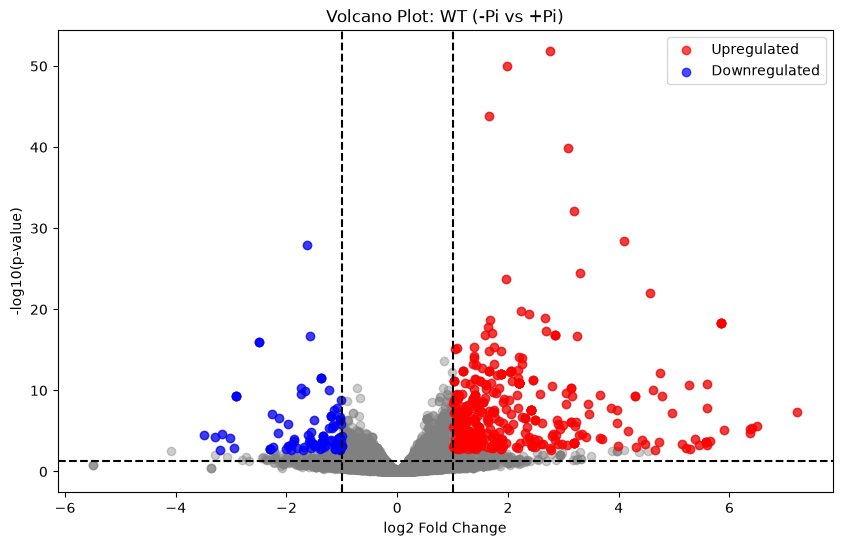

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

log2fc = df['fpkm_WT_nPvsWT_P_log2foldchange']
pval = df['fpkm_WT_nPvsWT_P_pvalue']

plt.figure(figsize=(10,6))
plt.scatter(log2fc, -np.log10(pval), alpha=0.4, color='gray')

# Highlight significant upregulated genes
plt.scatter(
    wt_up['fpkm_WT_nPvsWT_P_log2foldchange'],
    -np.log10(wt_up['fpkm_WT_nPvsWT_P_pvalue']),
    color='red', alpha=0.7, label='Upregulated'
)

# Highlight significant downregulated genes
plt.scatter(
    wt_down['fpkm_WT_nPvsWT_P_log2foldchange'],
    -np.log10(wt_down['fpkm_WT_nPvsWT_P_pvalue']),
    color='blue', alpha=0.7, label='Downregulated'
)

plt.axvline(1, color='black', linestyle='--')
plt.axvline(-1, color='black', linestyle='--')
plt.axhline(-np.log10(0.05), color='black', linestyle='--')

plt.xlabel("log2 Fold Change")
plt.ylabel("-log10(p-value)")
plt.title("Volcano Plot: WT (-Pi vs +Pi)")
plt.legend()
plt.show()


DEGs (differentially expressed genes ) for pdr2

In [22]:
pdr2_fc = df['fpkm_pdr2_nPvspdr2_P_log2foldchange']
pdr2_padj = df['fpkm_pdr2_nPvspdr2_P_padjust']

pdr2_up = df[(pdr2_fc > 1) & (pdr2_padj < 0.05)]
pdr2_down = df[(pdr2_fc < -1) & (pdr2_padj < 0.05)]

print("pdr2 upregulated genes:", pdr2_up.shape[0])
print("pdr2 downregulated genes:", pdr2_down.shape[0])


pdr2 upregulated genes: 2056
pdr2 downregulated genes: 1068


In [ ]:
pdr2_up.to_csv("../data/processed/pdr2_upregulated.csv", index=False)
pdr2_down.to_csv("../data/processed/pdr2_downregulated.csv", index=False)


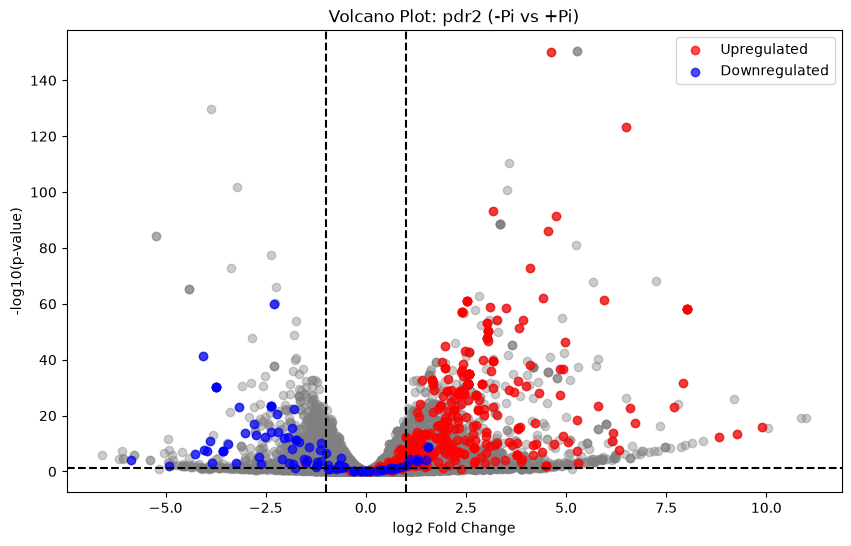

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

log2fc = df['fpkm_pdr2_nPvspdr2_P_log2foldchange']
pval = df['fpkm_pdr2_nPvspdr2_P_pvalue']

plt.figure(figsize=(10,6))
plt.scatter(log2fc, -np.log10(pval), alpha=0.4, color='gray')

# Highlight significant upregulated genes
plt.scatter(
    wt_up['fpkm_pdr2_nPvspdr2_P_log2foldchange'],
    -np.log10(wt_up['fpkm_pdr2_nPvspdr2_P_pvalue']),
    color='red', alpha=0.7, label='Upregulated'
)

# Highlight significant downregulated genes
plt.scatter(
    wt_down['fpkm_pdr2_nPvspdr2_P_log2foldchange'],
    -np.log10(wt_down['fpkm_pdr2_nPvspdr2_P_pvalue']),
    color='blue', alpha=0.7, label='Downregulated'
)

plt.axvline(1, color='black', linestyle='--')
plt.axvline(-1, color='black', linestyle='--')
plt.axhline(-np.log10(0.05), color='black', linestyle='--')

plt.xlabel("log2 Fold Change")
plt.ylabel("-log10(p-value)")
plt.title("Volcano Plot: pdr2 (-Pi vs +Pi)")
plt.legend()
plt.show()


DEGs (differentially expressed genes ) for l1l2

In [21]:
l1l2_fc = df['fpkm_l1l2_nPvsl1l2_P_log2foldchange']
l1l2_padj = df['fpkm_l1l2_nPvsl1l2_P_padjust']

l1l2_up = df[(l1l2_fc > 1) & (l1l2_padj < 0.05)]
l1l2_down = df[(l1l2_fc < -1) & (l1l2_padj < 0.05)]

print("l1l2 upregulated genes:", l1l2_up.shape[0])
print("l1l2 downregulated genes:", l1l2_down.shape[0])


l1l2 upregulated genes: 15
l1l2 downregulated genes: 2


In [ ]:
l1l2_up.to_csv("../data/processed/l1l2_upregulated.csv", index=False)
l1l2_down.to_csv("../data/processed/l1l2_downregulated.csv", index=False)


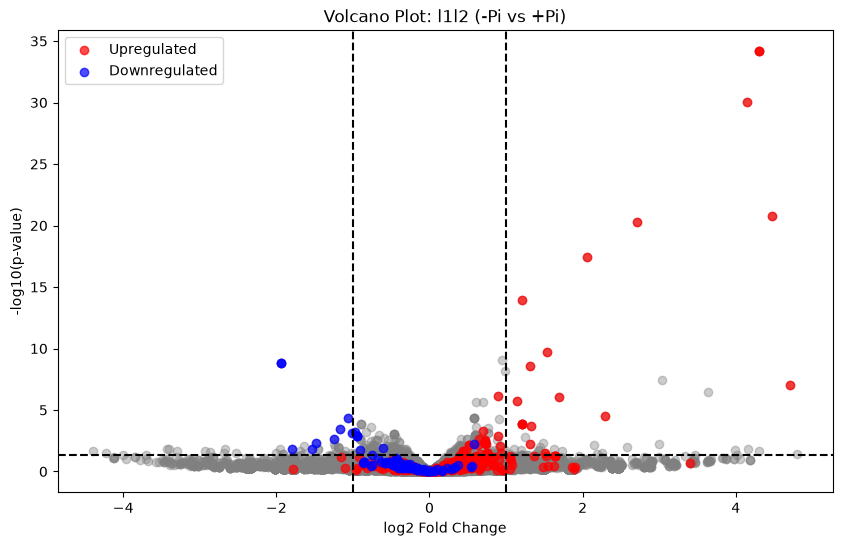

In [ ]:


log2fc = df['fpkm_l1l2_nPvsl1l2_P_log2foldchange']
pval = df['fpkm_l1l2_nPvsl1l2_P_pvalue']

plt.figure(figsize=(10,6))
plt.scatter(log2fc, -np.log10(pval), alpha=0.4, color='gray')

# Highlight significant upregulated genes
plt.scatter(
    wt_up['fpkm_l1l2_nPvsl1l2_P_log2foldchange'],
    -np.log10(wt_up['fpkm_l1l2_nPvsl1l2_P_pvalue']),
    color='red', alpha=0.7, label='Upregulated'
)

# Highlight significant downregulated genes
plt.scatter(
    wt_down['fpkm_l1l2_nPvsl1l2_P_log2foldchange'],
    -np.log10(wt_down['fpkm_l1l2_nPvsl1l2_P_pvalue']),
    color='blue', alpha=0.7, label='Downregulated'
)

plt.axvline(1, color='black', linestyle='--')
plt.axvline(-1, color='black', linestyle='--')
plt.axhline(-np.log10(0.05), color='black', linestyle='--')

plt.xlabel("log2 Fold Change")
plt.ylabel("-log10(p-value)")
plt.title("Volcano Plot: l1l2 (-Pi vs +Pi)")
plt.legend()
plt.show()

In [32]:
foldchange_cols = [
    'Gene_ID',
    'fpkm_WT_nPvsWT_P_log2foldchange',
    'fpkm_WT_nPvsWT_P_padjust',
    'fpkm_pdr2_nPvspdr2_P_log2foldchange',
    'fpkm_pdr2_nPvspdr2_P_padjust',
    'fpkm_l1l2_nPvsl1l2_P_log2foldchange',
    'fpkm_l1l2_nPvsl1l2_P_padjust'
]

df[foldchange_cols].to_csv("../data/processed/foldchange_raw.csv", index=False)



PCA (Principal Component Analysis)

Why:

PCA shows how samples cluster based on global expression patterns. This is the gold‑standard QC plot in RNA‑seq.

What it reveals:

Whether +Pi and –Pi separate clearly

Whether pdr2 behaves differently from WT

Whether l1l2 clusters closer to WT or pdr2

Whether any sample is an outlier

In [ ]:
%pip install scikit-learn

   ---------------------------------------- 0.0/8.4 MB ? eta -:--:--
   ------------ --------------------------- 2.6/8.4 MB 14.1 MB/s eta 0:00:01
   ------------------------------- -------- 6.6/8.4 MB 16.6 MB/s eta 0:00:01
   ---------------------------------------- 8.4/8.4 MB 17.1 MB/s  0:00:00
   ---------------------------------------- 0.0/37.4 MB ? eta -:--:--
   ------ --------------------------------- 5.8/37.4 MB 29.0 MB/s eta 0:00:02
   ------------ --------------------------- 12.1/37.4 MB 30.1 MB/s eta 0:00:01
   ------------------- -------------------- 18.1/37.4 MB 29.3 MB/s eta 0:00:01
   -------------------------- ------------- 24.9/37.4 MB 30.1 MB/s eta 0:00:01
   --------------------------------- ------ 31.2/37.4 MB 30.5 MB/s eta 0:00:01
   -------------------------------------- - 35.9/37.4 MB 29.1 MB/s eta 0:00:01
   ---------------------------------------- 37.4/37.4 MB 26.6 MB/s  0:00:01

   ------ --------------------------------- 1/6 [scipy]
   ------ -----------------


[notice] A new release of pip is available: 26.2.1 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


In [ ]:
expr_matrix = df[expr_cols].fillna(0).T


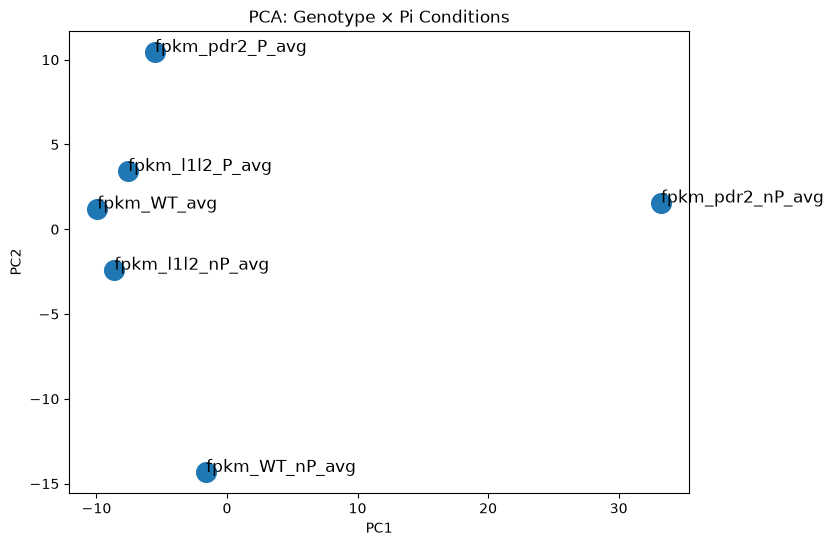

In [ ]:
from sklearn.decomposition import PCA
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

expr_cols = [
    "fpkm_WT_avg", "fpkm_WT_nP_avg",
    "fpkm_pdr2_P_avg", "fpkm_pdr2_nP_avg",
    "fpkm_l1l2_P_avg", "fpkm_l1l2_nP_avg"
]

# 1. Log-transform (fixes skew)
log_expr = np.log2(df[expr_cols].fillna(0) + 1)

# 2. Z-score normalize (makes PCA meaningful)
z_expr = (log_expr - log_expr.mean()) / log_expr.std()

# 3. PCA
pca = PCA(n_components=2)
pca_result = pca.fit_transform(z_expr.T)  # transpose: samples as rows

# 4. Plot
plt.figure(figsize=(8,6))
plt.scatter(pca_result[:,0], pca_result[:,1], s=200)

for i, label in enumerate(expr_cols):
    plt.text(pca_result[i,0], pca_result[i,1], label, fontsize=12)

plt.xlabel("PC1")
plt.ylabel("PC2")
plt.title("PCA: Genotype × Pi Conditions")
plt.show()




DEG Heatmap (WT DEGs across all genotypes)

In [ ]:
from scipy.cluster import hierarchy
from scipy.spatial import distance


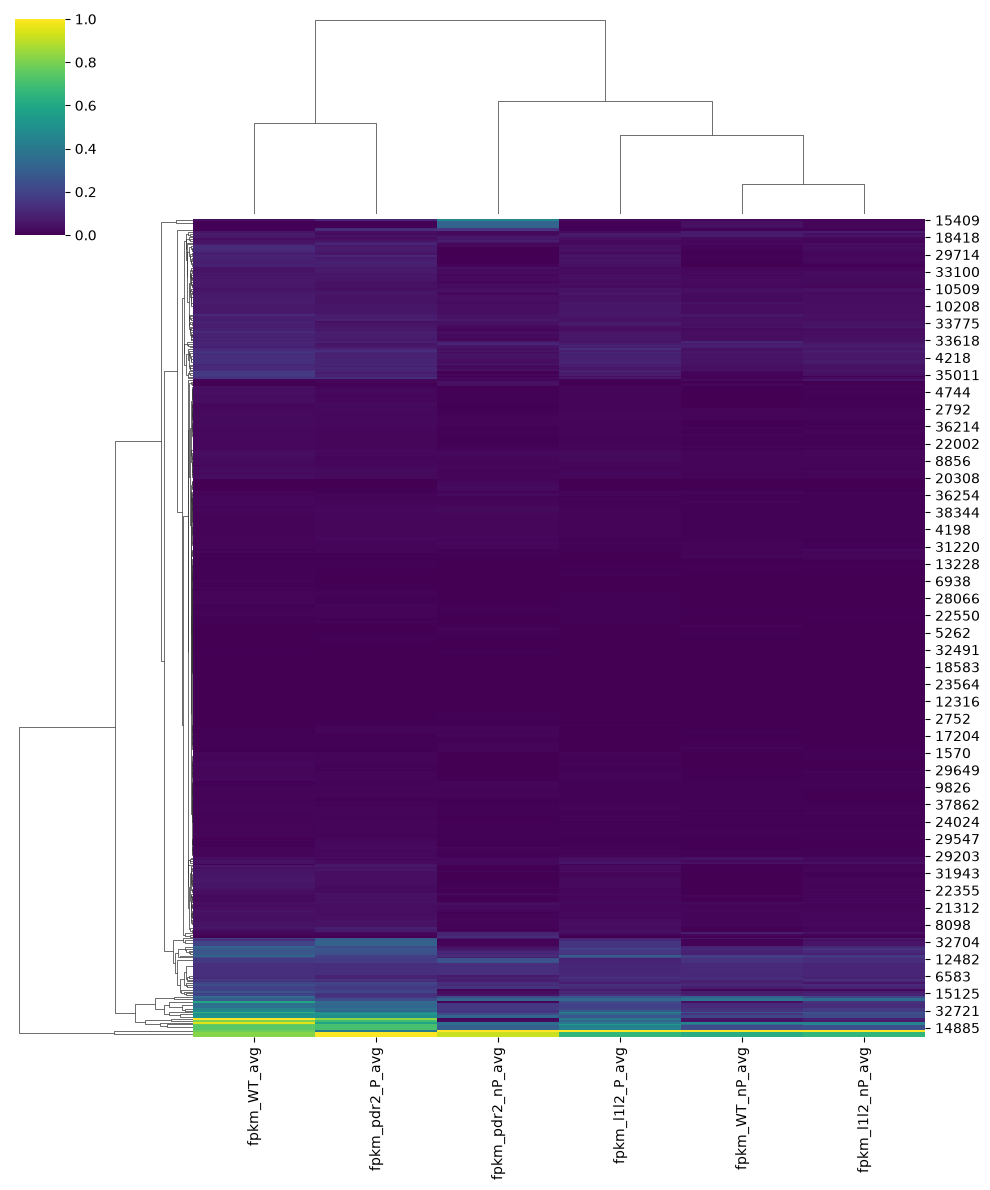

In [18]:
import seaborn as sns
import matplotlib.pyplot as plt

# Combine WT up and down DEGs
wt_deg = pd.concat([wt_up, wt_down])

expr_cols = [
    "fpkm_WT_avg", "fpkm_WT_nP_avg",
    "fpkm_pdr2_P_avg", "fpkm_pdr2_nP_avg",
    "fpkm_l1l2_P_avg", "fpkm_l1l2_nP_avg"
]

heatmap_data = wt_deg[expr_cols].fillna(0)

sns.clustermap(
    heatmap_data,
    cmap="viridis",
    standard_scale=1,
    figsize=(10, 12)
)
plt.show()


KOG (Eukaryotic Orthologous Groups)

Functional categories such as:

Signal transduction

Transcription

Transport

Metabolism

Stress response

Cell wall

Lipid metabolism

KOG tells you what type of genes are changing.

In [19]:
kog_counts = wt_deg['KOG Description'].value_counts().head(20)
kog_counts


KOG Description
.                                                                               388
Aldehyde dehydrogenase                                                           14
Predicted kinase                                                                  6
Proline oxidase                                                                   6
Dihydrolipoamide acetyltransferase                                                4
Asparagine synthase (glutamine-hydrolyzing)                                       4
Predicted protein tyrosine phosphatase                                            3
Cystathionine beta-lyases/cystathionine gamma-synthases                           3
Neutral trehalase                                                                 3
Palmitoyl protein thioesterase                                                    3
S-adenosylmethionine decarboxylase                                                3
Triglyceride lipase-cholesterol esterase                    

In [23]:
kog_counts_pdr2 = pd.concat([pdr2_up, pdr2_down])['KOG Description'].value_counts().head(20)
kog_counts_pdr2


KOG Description
.                                                                                         2377
Aldehyde dehydrogenase                                                                      42
Branched chain aminotransferase BCAT1, pyridoxal phosphate enzymes type IV superfamily      30
Glycolate oxidase                                                                           15
Acetyl-CoA acetyltransferase                                                                14
Fructose-1,6-bisphosphatase                                                                 10
Uncharacterized conserved protein                                                           10
Molecular chaperone (HSP90 family)                                                          10
Predicted esterase of the alpha-beta hydrolase superfamily                                   9
Salt-sensitive 3'-phosphoadenosine-5'-phosphatase HAL2/SAL1                                  9
NADP-dependent isocitrate dehydrog

In [24]:
kog_counts_l1l2 = pd.concat([l1l2_up, l1l2_down])['KOG Description'].value_counts().head(20)
kog_counts_l1l2


KOG Description
.                                                13
Predicted protein tyrosine phosphatase            2
Predicted starch-binding protein                  1
Permease of the major facilitator superfamily     1
Name: count, dtype: int64

KEGG (Kyoto Encyclopedia of Genes and Genomes)

Biological pathways such as:

Phosphate transport

Lipid remodeling

Organic acid metabolism

Hormone signaling

Root development

Energy metabolism

KEGG tells you which pathways are changing.

In [25]:
kegg_counts = wt_deg['kegg_pathway_name'].value_counts().head(20)
kegg_counts


kegg_pathway_name
.                                             318
Metabolic pathways                             39
Biosynthesis of secondary metabolites          24
Starch and sucrose metabolism                   8
Plant hormone signal transduction               7
Arginine and proline metabolism                 4
Nitrogen metabolism                             4
Cysteine and methionine metabolism              4
Ascorbate and aldarate metabolism               3
Glycerolipid metabolism                         3
Phenylpropanoid biosynthesis                    3
Glycerophospholipid metabolism                  3
Ubiquitin mediated proteolysis                  3
Zeatin biosynthesis                             2
Glycolysis / Gluconeogenesis                    2
Valine, leucine and isoleucine degradation      2
Pyruvate metabolism                             2
Pyrimidine metabolism                           2
Carbon metabolism                               2
Inositol phosphate metabolism   

In [27]:
kegg_counts_pdr2 = pd.concat([pdr2_up, pdr2_down])['kegg_pathway_name'].value_counts().head(40)
kegg_counts_pdr2


kegg_pathway_name
.                                                         1971
Metabolic pathways                                         246
Biosynthesis of secondary metabolites                      148
Ribosome                                                    52
Plant-pathogen interaction                                  36
Plant hormone signal transduction                           35
Phenylpropanoid biosynthesis                                27
Carbon metabolism                                           26
Starch and sucrose metabolism                               22
MAPK signaling pathway - plant                              19
Glutathione metabolism                                      19
Protein processing in endoplasmic reticulum                 18
Photosynthesis                                              16
Pentose and glucuronate interconversions                    16
Cysteine and methionine metabolism                          15
Peroxisome                           

In [29]:
kegg_counts_l1l2 = pd.concat([l1l2_up, l1l2_down])['kegg_pathway_name'].value_counts().head(40)
kegg_counts_l1l2


kegg_pathway_name
.                                 12
Metabolic pathways                 2
Glycerophospholipid metabolism     1
Riboflavin metabolism              1
Glycerolipid metabolism            1
Name: count, dtype: int64